# Structure generation: IR + Raman

Generate structures from molecular spectra.

The openSpec model encodes the spectral channels with Vib2Mol. Generation uses beam search and molecular matching scores; retrieval compares embeddings, and candidate reranking uses the matching head.

This tutorial loads the saved predictions, explains the input/output fields and evaluates the results. Use the final command to run the model on a new dataset.

In [1]:
import json, sys, io
from pathlib import Path
from IPython.display import display, Markdown, SVG
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'openmolspec_bench').is_dir()), None)
if root is None:
    raise RuntimeError('Run from the cloned release repository; see Quick Start')
sys.path.insert(0, str(root / 'scripts'))
from documentation_evidence import load_evidence, compact, recompute, render
from documentation_content import results_table
evidence = load_evidence('vibrational.generation')
print('Task:', evidence['task'])
print('Examples:', len(evidence['examples']))

Task: vibrational.generation
Examples: 3


## Inputs and outputs

| Field | Meaning |
| --- | --- |
| `IR / Raman` | 1024 intensity samples per visible channel, ordered 400→4000 cm⁻¹, using the checkpoint normalization. |
| `missing channels` | The input mask selects visible channels from the shared four-modal checkpoint. |

| Field | Meaning |
| --- | --- |
| `SMILES candidates` | Decoded valid, canonical unique candidates; full-input route uses beam 10 and ITM reranking. |
| `top-k` | Generation and reranking scores are separate. No molecular formula is supplied. |

Inspect the example records below. Long arrays show their length and first values; the downloadable JSON contains the complete arrays.

In [2]:
for example in evidence['examples'][:3]:
    print(json.dumps(compact(example), indent=2, ensure_ascii=False))

{
  "reference": "CCCCc1cc2ccccc2c(OCCN(C)C)n1",
  "raw_top_1": "N1=NN2N=NN=C2N1",
  "canonical_top_1": "n1nc2[nH]nnn2n1",
  "input": {
    "ir": {
      "length": 1024,
      "first_values": [
        0.012721044011414051,
        0.012162876315414906,
        0.011645566672086716,
        0.010846862569451332,
        0.009556070901453495,
        0.008287975564599037,
        0.007421660702675581,
        0.006977375131100416
      ]
    },
    "raman": {
      "length": 1024,
      "first_values": [
        0.026861174032092094,
        0.022829052060842514,
        0.02229130268096924,
        0.0217174980789423,
        0.01772497035562992,
        0.015520459040999413,
        0.016201019287109375,
        0.01993374526500702
      ]
    }
  }
}
{
  "reference": "N#CSCSc1nc2ccccc2s1",
  "raw_top_1": "N1=NN=NN1N1N=NN=N1",
  "canonical_top_1": "n1nnn(-n2nnnn2)n1"
}
{
  "reference": "CC12CCC(=O)C=C1CCC1C2CCC2(C)C(C(=O)CO)CCC12",
  "raw_top_1": "N1=NN2N=NN=C2N1",
  "canonical_top_1"

## Evaluate the predictions

Report top-k accuracy for generation, and Recall@k/MRR for ranking.

The table gives the dataset and metric for each run. The following calculation recomputes summary values from the plotted predictions.

In [3]:
display(Markdown(results_table(evidence, True)))
print(json.dumps(recompute(evidence), indent=2, ensure_ascii=False))

| Dataset / scope | Model / variant | Metric | Value |
| --- | --- | --- | ---: |
| recorded sample | recorded model | valid_rate | 1 |
| recorded sample | recorded model | exact_rate | 0 |
| recorded sample | recorded model | examples | 4 |


{
  "top1_matches_reference_this_example": false
}


## Visualize the result

Reference structure and generated candidates.

Compare the prediction with the reference and inspect the returned structures or peak positions. The plot is generated directly from the records loaded above.

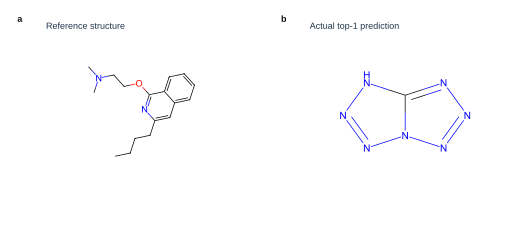

In [4]:
import matplotlib.pyplot as plt
for example_index in range(1):
    figure = render('vibrational.generation', evidence, example_index=example_index)
    image = io.StringIO()
    figure.savefig(image, format='svg', metadata={'Date': None})
    display(SVG(image.getvalue()))
    plt.close(figure)

## Run the model

Configure the runtime and weights following the task guide. Select this task in the benchmark runner to evaluate your dataset.

```bash
python -m openmolspec_bench run --workspace /path/to/OpenMolSpec \
  --tasks vibrational.generation --limit 8 --output results/vibrational-generation.json
```

[Task](../tasks/vibrational-generation.md) · [Quick start](../quickstart.md)



## References

- OpenMolSpec contributors. openSpec models and benchmark training workflows. Source archive, v1.0 (2026). [Source](https://github.com/jiaqingxie/openmolspec-studio-frontend/tree/release/openmolspec-v1/documentation/assets/benchmarks)
- OpenMolSpec contributors. OpenMolSpec: Chemical spectroscopy datasets, models and learning workflows. Software release v1.0 (2026). [Source](https://github.com/jiaqingxie/openmolspec-studio-frontend/releases/tag/v1.0)
- Yuan, M., Zou, Z. & Hu, W. QMe14S, A Comprehensive and Efficient Spectral Dataset for Small Organic Molecules. arXiv:2501.18876 (2025). [Source](https://arxiv.org/abs/2501.18876)
- Zou, Z., Zhang, Y., Liang, L., Wei, M., Leng, J., Jiang, J., Luo, Y. & Hu, W. A deep learning model for predicting selected organic molecular spectra. Nature Computational Science 3, 957–964 (2023). doi:10.1038/s43588-023-00550-y. [Source](https://www.nature.com/articles/s43588-023-00550-y)
